In [19]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')

In [20]:
def load_ismn(file_path):
    with open(file_path, 'r') as f:
        header = f.readline().strip().split()

    try:
        network, station = header[1], header[2]
        lat, lon = float(header[3]), float(header[4])
    except (IndexError, ValueError):
        return None

    df = pd.read_csv(
        file_path,
        sep=r'\s+',
        skiprows=1,
        header=None,
        engine='python'
    )

    if df.shape[1] < 4:
        return None

    df = df.iloc[:, :4]
    df.columns = ['date', 'time', 'sm', 'flag']

    # Filter for Good quality
    df = df[df['flag'] == 'G']
    if df.empty:
        return None

    # Cleaning
    df['timestamp'] = pd.to_datetime(df['date'] + ' ' + df['time'])
    df['sm'] = pd.to_numeric(df['sm'], errors='coerce')
    df = df.dropna(subset=['sm'])

    # Unit conversion (Percentage to m3/m3)
    if df['sm'].mean() > 1.0:
        df['sm'] = df['sm'] / 100.0

    df['point_id'] = f"{network}_{station}"
    df['latitude'] = lat
    df['longitude'] = lon

    return df[['point_id', 'timestamp', 'sm', 'latitude', 'longitude']]

# --- EXECUTION (same path/pattern as CNN_Spain) ---
stm_files = glob.glob('Data/Spain/REMEDHUS/*/*.stm', recursive=True)
print(f'STM files found: {len(stm_files)}')

dfs = [load_ismn(f) for f in stm_files]
dfs = [d for d in dfs if d is not None]
if len(dfs) == 0:
    raise ValueError('No valid STM files after parsing and quality filtering.')

df_combined = pd.concat(dfs, ignore_index=True)

# 1) MULTI-SENSOR COLLAPSE (A/B/C duplicate sensors at same timestamp)
ground_truth = df_combined.groupby(
    ['point_id', 'timestamp', 'latitude', 'longitude'], as_index=False
)["sm"].mean()

# 2) DAILY AGGREGATION
ground_truth['timestamp'] = (
    ground_truth['timestamp']
    .dropna()
    .dt.floor('D')
)

ground_truth = ground_truth.groupby(
    ['point_id', 'timestamp', 'latitude', 'longitude'], as_index=False
)["sm"].mean()

df = ground_truth.copy()
print(f'Final ground truth shape: {df.shape}')
print(f'Unique stations: {df["point_id"].nunique()}')
df.head()

STM files found: 20
Final ground truth shape: (72265, 5)
Unique stations: 20


,point_id,timestamp,latitude,longitude,sm
0,REMEDHUS_Canizal,2014-05-01,41.19603,-5.35997,0.230500
1,REMEDHUS_Canizal,2014-05-02,41.19603,-5.35997,0.211875
2,REMEDHUS_Canizal,2014-05-03,41.19603,-5.35997,0.200333
3,REMEDHUS_Canizal,2014-05-04,41.19603,-5.35997,0.314143
4,REMEDHUS_Canizal,2014-05-05,41.19603,-5.35997,0.281708


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72265 entries, 0 to 72264
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   point_id   72265 non-null  object        
 1   timestamp  72265 non-null  datetime64[ns]
 2   latitude   72265 non-null  float64       
 3   longitude  72265 non-null  float64       
 4   sm         72265 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(1)
memory usage: 2.8+ MB


In [22]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
point_id,0,0.0
timestamp,0,0.0
latitude,0,0.0
longitude,0,0.0
sm,0,0.0


In [23]:
dup_exact = df.duplicated().sum()
dup_key = df.duplicated(subset=['point_id', 'timestamp']).sum()
print(f'Exact duplicates: {dup_exact}')
print(f'Duplicates by point_id+timestamp: {dup_key}')

bounds = {
    'sm_lt_0': int((df['sm'] < 0).sum()),
    'sm_gt_1': int((df['sm'] > 1).sum()),
    'sm_na': int(df['sm'].isna().sum()),
}
print(bounds)

Exact duplicates: 0
Duplicates by point_id+timestamp: 0
{'sm_lt_0': 0, 'sm_gt_1': 0, 'sm_na': 0}


count    72265.000000
mean         0.121745
std          0.098407
min          0.000000
1%           0.000087
5%           0.005013
25%          0.041583
50%          0.099000
75%          0.184625
95%          0.310583
99%          0.408864
max          0.503000
Name: sm, dtype: float64


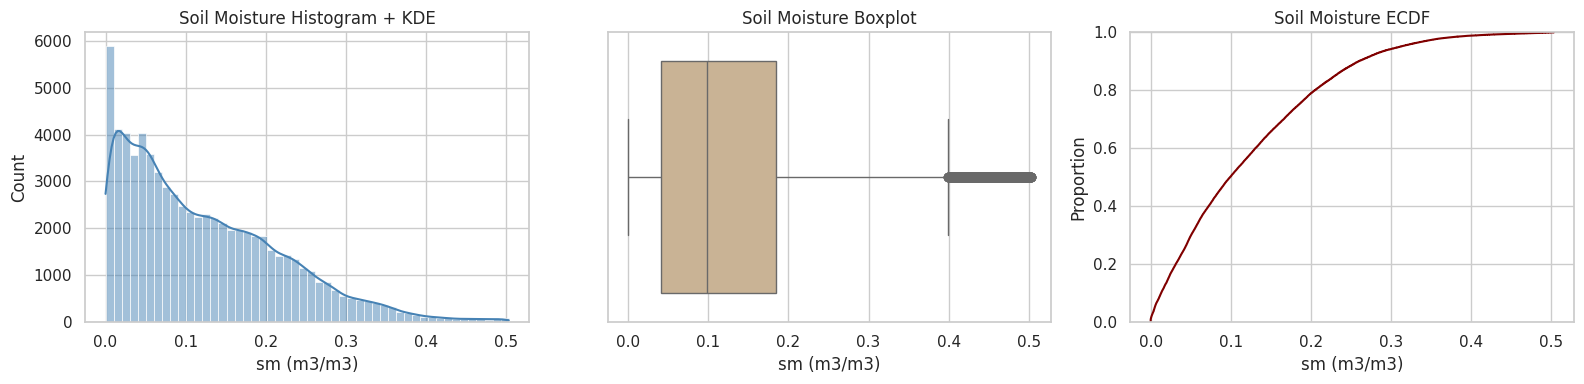

In [24]:
print(df['sm'].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['sm'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Soil Moisture Histogram + KDE')
axes[0].set_xlabel('sm (m3/m3)')

sns.boxplot(x=df['sm'], ax=axes[1], color='tan')
axes[1].set_title('Soil Moisture Boxplot')
axes[1].set_xlabel('sm (m3/m3)')

sns.ecdfplot(df['sm'], ax=axes[2], color='maroon')
axes[2].set_title('Soil Moisture ECDF')
axes[2].set_xlabel('sm (m3/m3)')

plt.tight_layout()
plt.show()

Time range: 2014-05-01 00:00:00 to 2025-01-01 00:00:00


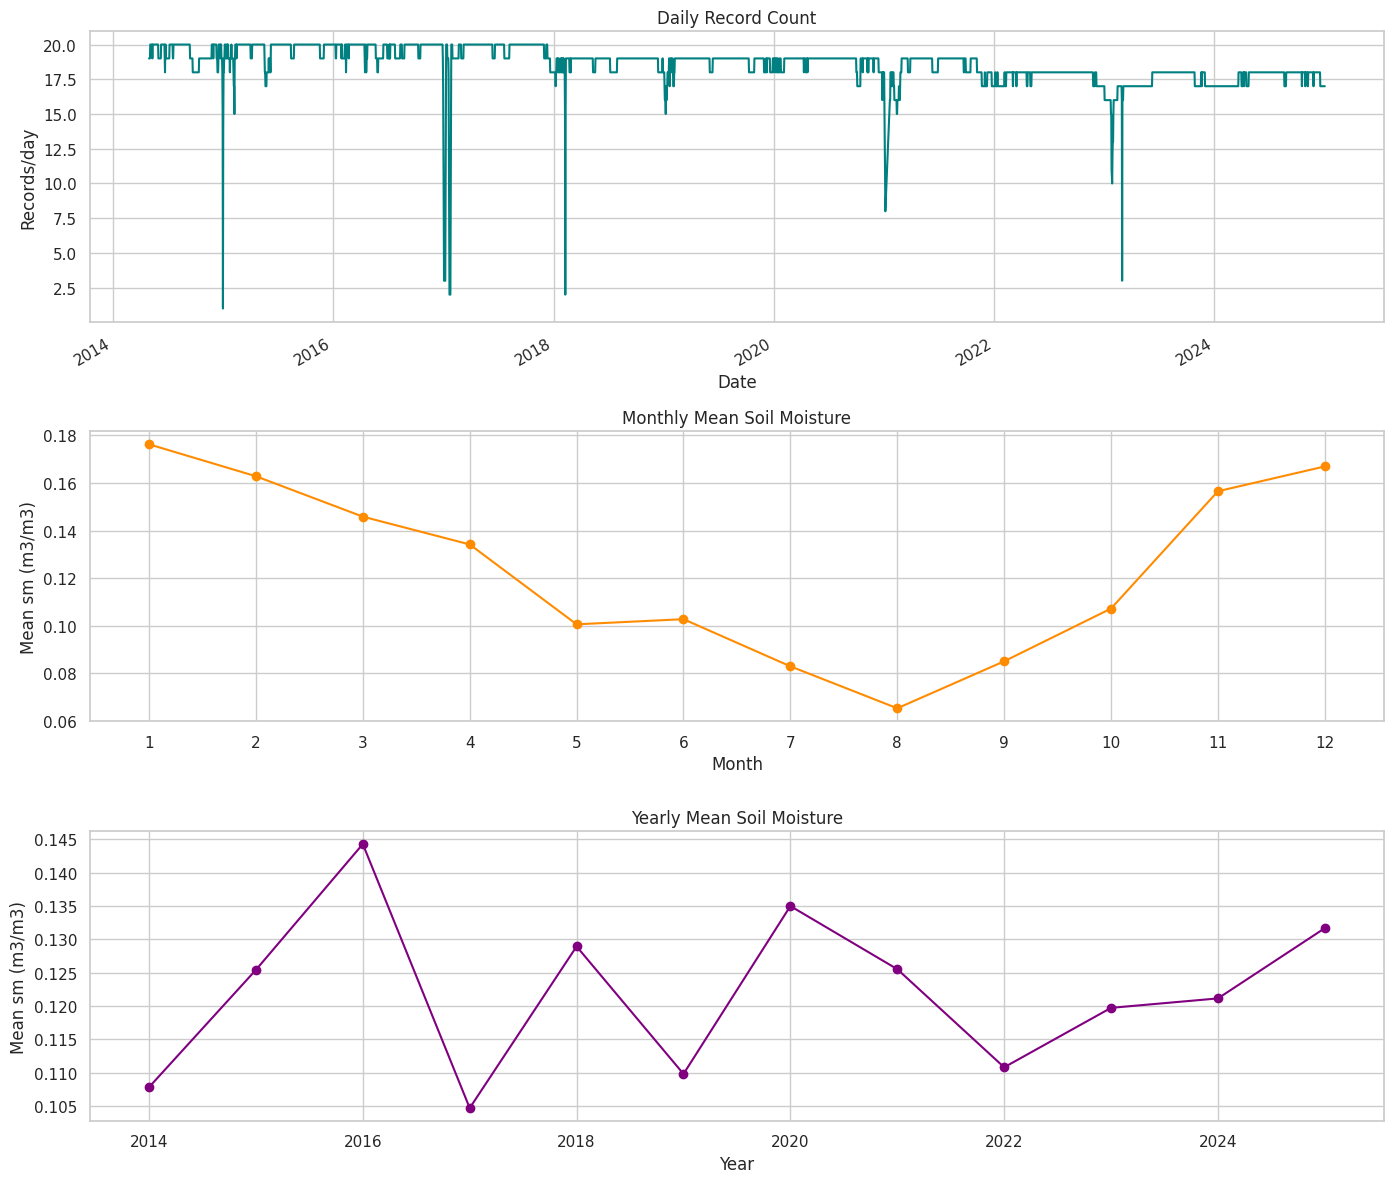

In [25]:
print('Time range:', df['timestamp'].min(), 'to', df['timestamp'].max())

daily_counts = df.groupby('timestamp').size().sort_index()
monthly_mean = df.assign(month=df['timestamp'].dt.month).groupby('month')['sm'].mean().reindex(range(1, 13))
yearly_mean = df.assign(year=df['timestamp'].dt.year).groupby('year')['sm'].mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
daily_counts.plot(ax=axes[0], color='teal')
axes[0].set_title('Daily Record Count')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Records/day')

monthly_mean.plot(ax=axes[1], marker='o', color='darkorange')
axes[1].set_title('Monthly Mean Soil Moisture')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Mean sm (m3/m3)')
axes[1].set_xticks(range(1, 13))

yearly_mean.plot(ax=axes[2], marker='o', color='purple')
axes[2].set_title('Yearly Mean Soil Moisture')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Mean sm (m3/m3)')

plt.tight_layout()
plt.show()

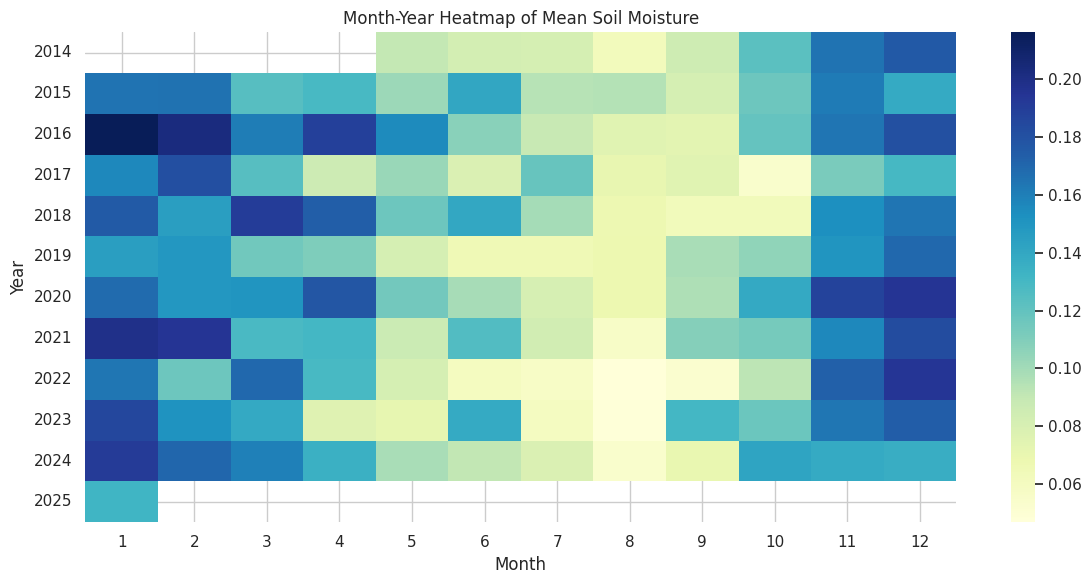

In [26]:
month_year = df.assign(year=df['timestamp'].dt.year, month=df['timestamp'].dt.month) \
    .pivot_table(index='year', columns='month', values='sm', aggfunc='mean')

plt.figure(figsize=(12, 6))
sns.heatmap(month_year, cmap='YlGnBu', annot=False)
plt.title('Month-Year Heatmap of Mean Soil Moisture')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

Unique stations: 20


,count,mean,std,min,max
point_id,,,,,
REMEDHUS_Zamarron,3860,0.080896,0.051117,0.008542,0.211167
REMEDHUS_Las_Victorias,3847,0.027741,0.024092,0.000000,0.107708
REMEDHUS_Casa_Periles,3843,0.119367,0.050799,0.041875,0.233917
REMEDHUS_Las_Arenas,3842,0.184671,0.074864,0.033130,0.396417
REMEDHUS_La_Cruz_de_Elias,3833,0.151101,0.072488,0.004137,0.337250
REMEDHUS_Concejo_del_Monte,3831,0.180042,0.073793,0.040500,0.383292
REMEDHUS_Llanos_de_la_Boveda,3828,0.190631,0.087688,0.000000,0.502250
REMEDHUS_Las_Vacas,3828,0.084202,0.049744,0.004870,0.234667
REMEDHUS_Las_Tres_Rayas,3824,0.079385,0.066985,0.000000,0.376870


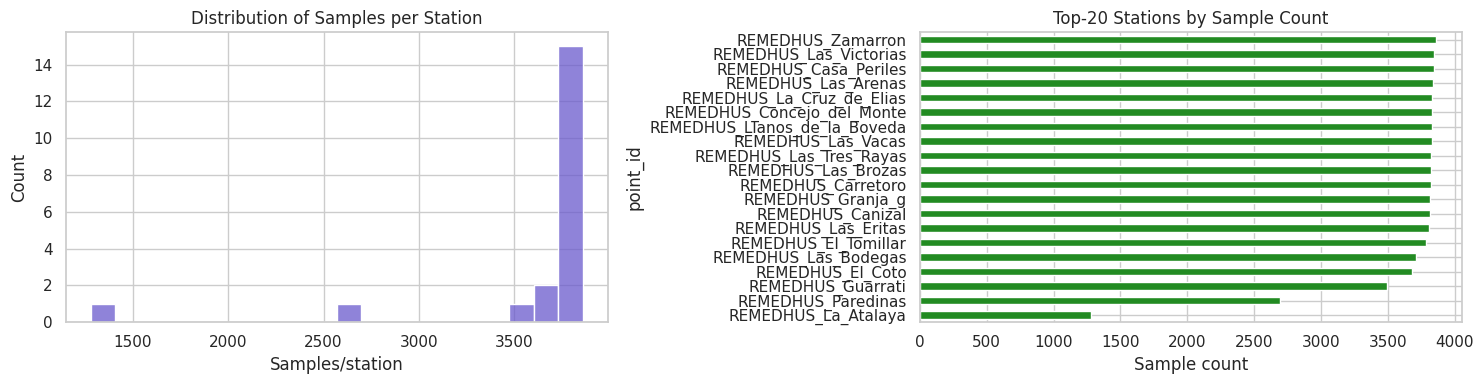

In [27]:
station_counts = df['point_id'].value_counts()
station_stats = df.groupby('point_id')['sm'].agg(['count', 'mean', 'std', 'min', 'max']).sort_values('count', ascending=False)
print('Unique stations:', station_counts.size)
display(station_stats.head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(station_counts, bins=20, ax=axes[0], color='slateblue')
axes[0].set_title('Distribution of Samples per Station')
axes[0].set_xlabel('Samples/station')

top20 = station_counts.head(20).sort_values()
top20.plot(kind='barh', ax=axes[1], color='forestgreen')
axes[1].set_title('Top-20 Stations by Sample Count')
axes[1].set_xlabel('Sample count')

plt.tight_layout()
plt.show()

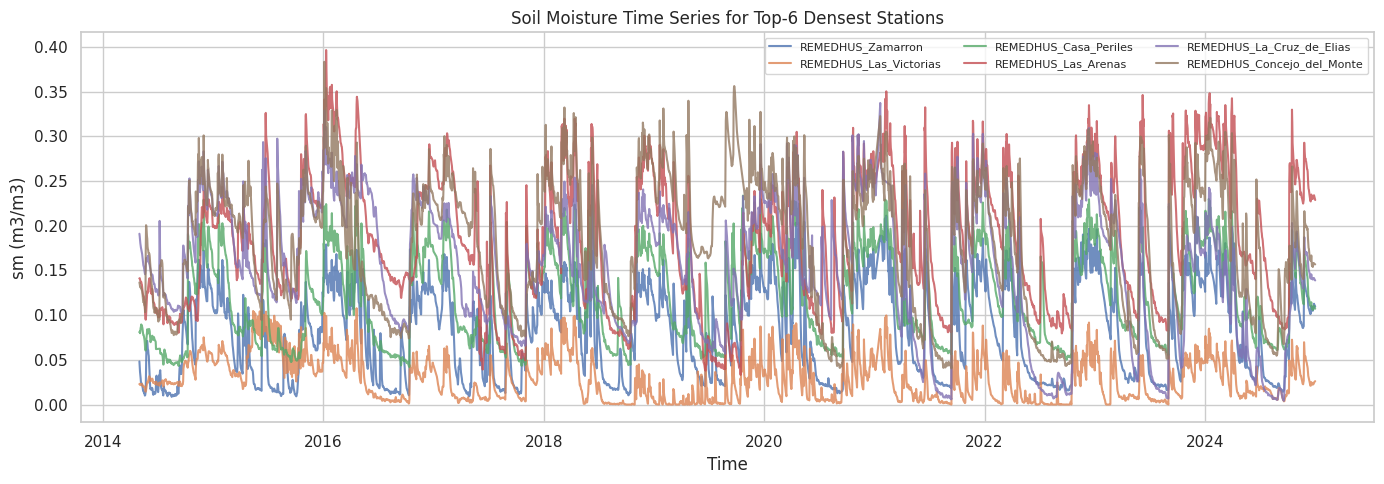

In [28]:
top_stations = station_counts.head(6).index.tolist()
plt.figure(figsize=(14, 5))
for pid in top_stations:
    s = df[df['point_id'] == pid].sort_values('timestamp')
    plt.plot(s['timestamp'], s['sm'], alpha=0.8, label=str(pid))
plt.title('Soil Moisture Time Series for Top-6 Densest Stations')
plt.xlabel('Time')
plt.ylabel('sm (m3/m3)')
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

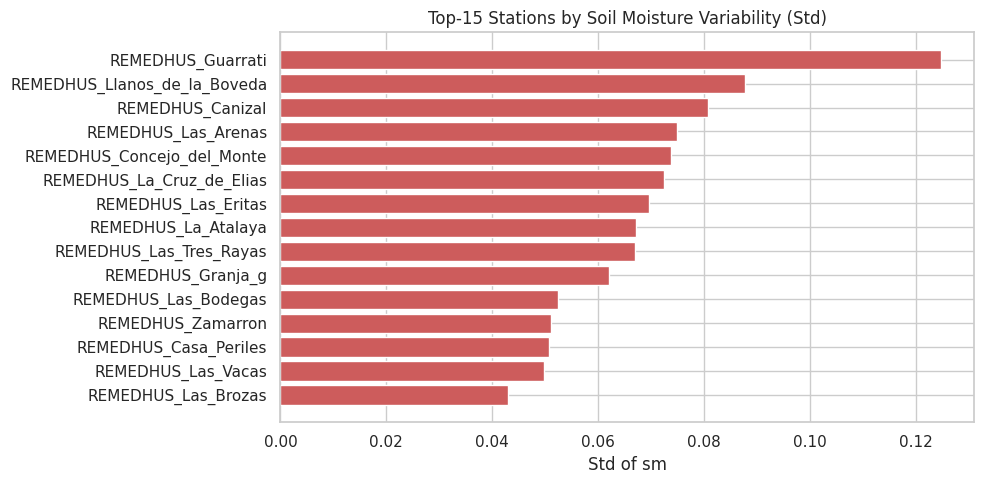

In [29]:
top_var = station_stats.sort_values('std', ascending=False).head(15)
plt.figure(figsize=(10, 5))
plt.barh(top_var.index[::-1], top_var['std'][::-1], color='indianred')
plt.title('Top-15 Stations by Soil Moisture Variability (Std)')
plt.xlabel('Std of sm')
plt.tight_layout()
plt.show()

Lat range: 41.14894 41.45586
Lon range: -5.5919 -5.22474


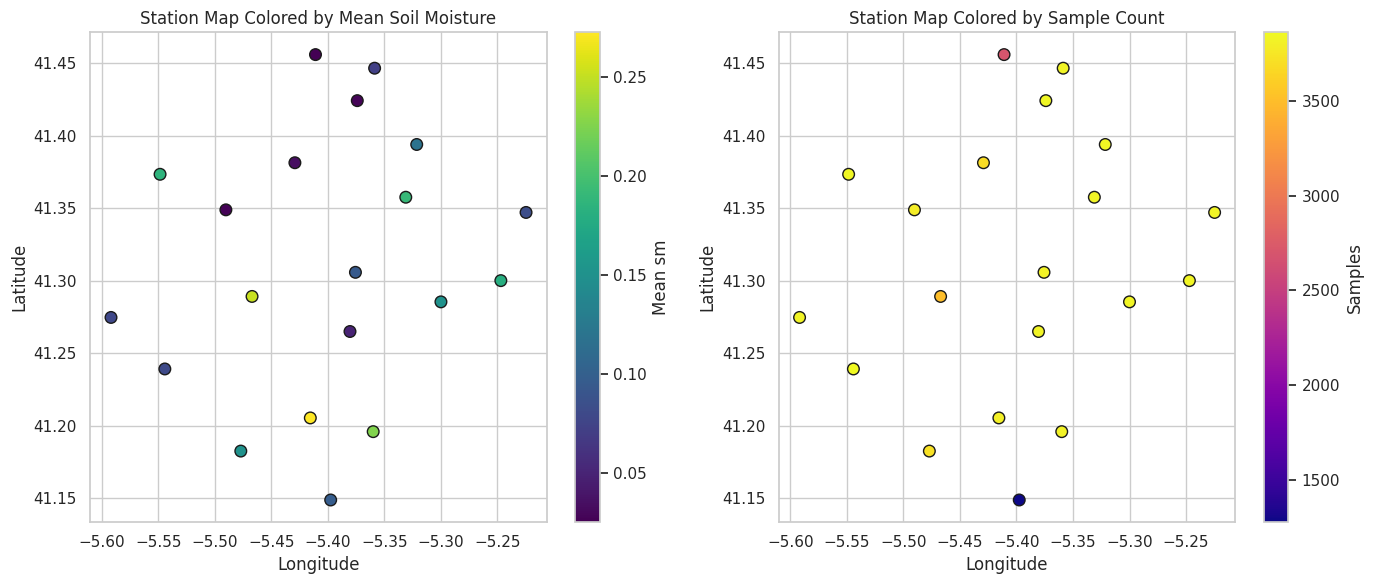

In [30]:
station_geo = df.groupby('point_id', as_index=False).agg(
    latitude=('latitude', 'first'),
    longitude=('longitude', 'first'),
    sm_mean=('sm', 'mean'),
    sm_std=('sm', 'std'),
    samples=('sm', 'size')
)

print('Lat range:', station_geo['latitude'].min(), station_geo['latitude'].max())
print('Lon range:', station_geo['longitude'].min(), station_geo['longitude'].max())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc1 = axes[0].scatter(station_geo['longitude'], station_geo['latitude'], c=station_geo['sm_mean'], s=70, cmap='viridis', edgecolor='k')
axes[0].set_title('Station Map Colored by Mean Soil Moisture')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
plt.colorbar(sc1, ax=axes[0], label='Mean sm')

sc2 = axes[1].scatter(station_geo['longitude'], station_geo['latitude'], c=station_geo['samples'], s=70, cmap='plasma', edgecolor='k')
axes[1].set_title('Station Map Colored by Sample Count')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
plt.colorbar(sc2, ax=axes[1], label='Samples')

plt.tight_layout()
plt.show()

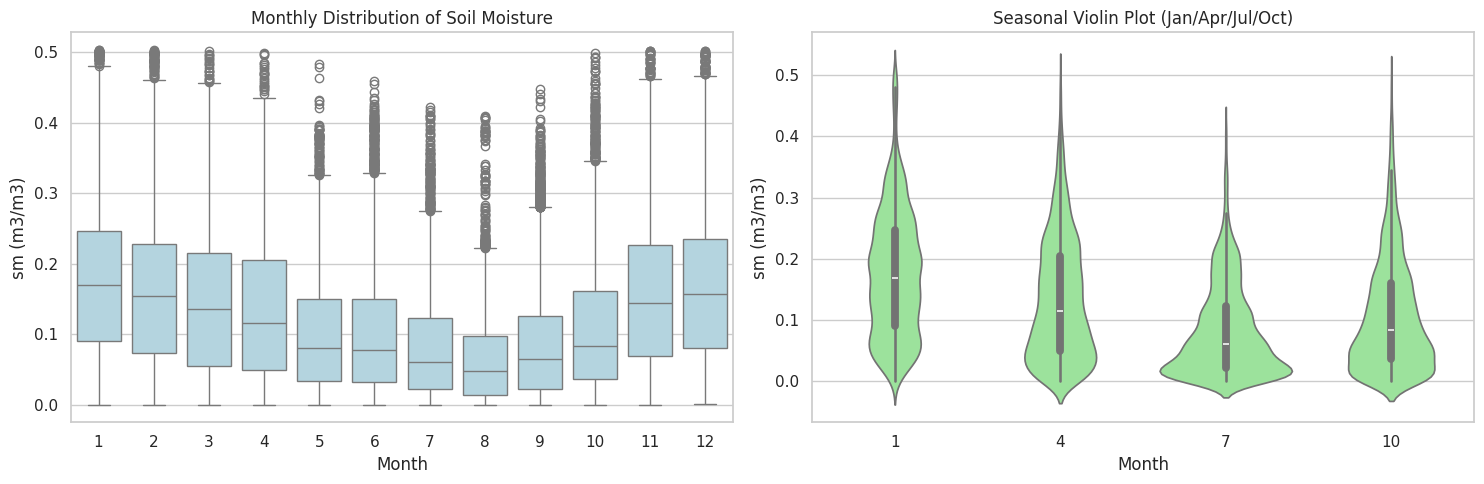

In [31]:
tmp = df.copy()
tmp['month'] = tmp['timestamp'].dt.month
tmp['year'] = tmp['timestamp'].dt.year

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=tmp, x='month', y='sm', ax=axes[0], color='lightblue')
axes[0].set_title('Monthly Distribution of Soil Moisture')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('sm (m3/m3)')

sns.violinplot(data=tmp[tmp['month'].isin([1, 4, 7, 10])], x='month', y='sm', ax=axes[1], color='lightgreen')
axes[1].set_title('Seasonal Violin Plot (Jan/Apr/Jul/Oct)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('sm (m3/m3)')

plt.tight_layout()
plt.show()

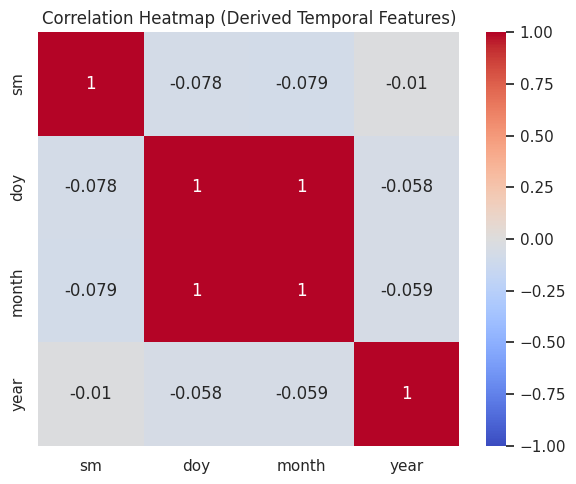

In [32]:
daily_station = df.groupby(['point_id', 'timestamp'], as_index=False)['sm'].mean()
daily_station['doy'] = daily_station['timestamp'].dt.dayofyear
daily_station['month'] = daily_station['timestamp'].dt.month
daily_station['year'] = daily_station['timestamp'].dt.year

corr_df = daily_station[['sm', 'doy', 'month', 'year']].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr_df, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap (Derived Temporal Features)')
plt.tight_layout()
plt.show()

Quantile bounds: q01=0.0001, q99=0.4089
Potential outliers: 1433/72265 (1.98%)


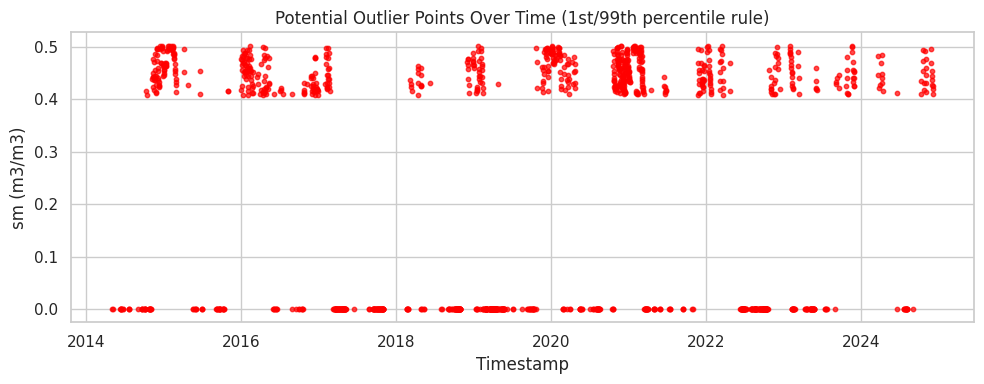

In [33]:
q01, q99 = df['sm'].quantile([0.01, 0.99])
outlier_mask = (df['sm'] < q01) | (df['sm'] > q99)
print(f'Quantile bounds: q01={q01:.4f}, q99={q99:.4f}')
print(f'Potential outliers: {int(outlier_mask.sum())}/{len(df)} ({100*outlier_mask.mean():.2f}%)')

plt.figure(figsize=(10, 4))
plt.scatter(df.loc[outlier_mask, 'timestamp'], df.loc[outlier_mask, 'sm'], s=10, alpha=0.7, color='red')
plt.title('Potential Outlier Points Over Time (1st/99th percentile rule)')
plt.xlabel('Timestamp')
plt.ylabel('sm (m3/m3)')
plt.tight_layout()
plt.show()

In [37]:
from pathlib import Path
from tfrecord.reader import tfrecord_loader

TFRECORD_PATH = Path('Data/Spain/ML_ready_1km_patches_spain.tfrecord.gz')
if not TFRECORD_PATH.exists():
    raise FileNotFoundError(f'Missing TFRecord file: {TFRECORD_PATH}')

features = [
    'NDVI', 'VV', 'VH', 'VV_VH_Ratio', 'angle',
    'LST', 'SMAP', 'precip', 'VPD', 'API', 'Albedo',
    'clay', 'sand', 'silt', 'elevation', 'slope', 'aspect'
 ]

description = {f: 'float' for f in features}
description['point_id'] = 'byte'
description['timestamp'] = 'float'

print(f'TFRecord path: {TFRECORD_PATH}')
print(f'Feature count: {len(features)}')

TFRecord path: Data/Spain/ML_ready_1km_patches_spain.tfrecord.gz
Feature count: 17


In [38]:
MAX_SAMPLES = 3000
samples = []
loader = tfrecord_loader(str(TFRECORD_PATH), None, description, compression_type='gzip')

for i, record in enumerate(loader):
    if i >= MAX_SAMPLES:
        break

    row = {}
    for feat in features:
        arr = np.asarray(record[feat], dtype=np.float32)
        if arr.size != 169:
            row[f'{feat}_center'] = np.nan
            row[f'{feat}_mean'] = np.nan
            row[f'{feat}_std'] = np.nan
            continue

        patch = arr.reshape(13, 13)
        row[f'{feat}_center'] = float(patch[6, 6])
        row[f'{feat}_mean'] = float(np.nanmean(patch))
        row[f'{feat}_std'] = float(np.nanstd(patch))

    pid_raw = record.get('point_id', b'')
    row['point_id'] = pid_raw.decode('utf-8') if isinstance(pid_raw, (bytes, bytearray)) else str(pid_raw)
    ts_raw = record.get('timestamp', np.nan)
    ts_val = float(np.asarray(ts_raw).reshape(-1)[0]) if np.asarray(ts_raw).size else np.nan
    row['timestamp_ms'] = ts_val
    row['timestamp'] = pd.to_datetime(ts_val, unit='ms', errors='coerce')
    samples.append(row)

tfrecord_df = pd.DataFrame(samples)
print(f'Sampled records: {len(tfrecord_df)}')
print(f'Unique stations in sample: {tfrecord_df["point_id"].nunique()}')
print('Time range:', tfrecord_df['timestamp'].min(), 'to', tfrecord_df['timestamp'].max())
tfrecord_df.head()

Sampled records: 3000
Unique stations in sample: 20
Time range: 2015-07-01 00:00:17.408000 to 2015-11-27 00:00:47.104000


,NDVI_center,NDVI_mean,NDVI_std,VV_center,VV_mean,VV_std,VH_center,VH_mean,VH_std,VV_VH_Ratio_center,VV_VH_Ratio_mean,VV_VH_Ratio_std,angle_center,angle_mean,angle_std,LST_center,LST_mean,LST_std,SMAP_center,SMAP_mean,SMAP_std,precip_center,precip_mean,precip_std,VPD_center,VPD_mean,VPD_std,API_center,API_mean,API_std,Albedo_center,Albedo_mean,Albedo_std,clay_center,clay_mean,clay_std,sand_center,sand_mean,sand_std,silt_center,silt_mean,silt_std,elevation_center,elevation_mean,elevation_std,slope_center,slope_mean,slope_std,aspect_center,aspect_mean,aspect_std,point_id,timestamp_ms,timestamp
0,0.375397,0.375398,0.002623,-13.893388,-13.893373,0.079892,-18.521900,-18.521906,0.033033,4.425515,4.425534,0.102349,37.165154,37.165184,0.117523,21.047907,21.047903,0.022430,0.103282,0.103282,0.001567,0.000009,0.000009,4.320337e-07,2.145907,2.145904,0.014491,0.0,0.0,0.0,0.162608,0.162607,0.000410,194.0,204.514786,16.657391,644.0,623.502930,25.830837,163.0,172.733734,14.744575,793.0,792.692322,35.027630,1.088163,0.997338,0.495581,82.347595,145.149414,112.885765,REMEDHUS_Canizal,1.435709e+12,2015-07-01 00:00:17.408
1,0.369827,0.369828,0.002586,-13.976410,-13.976395,0.083580,-18.481651,-18.481659,0.030355,4.309378,4.309398,0.102368,36.945126,36.945156,0.117404,21.073425,21.073421,0.023940,0.104934,0.104934,0.001632,0.000009,0.000009,4.429380e-07,2.162356,2.162353,0.014533,0.0,0.0,0.0,0.163088,0.163088,0.000452,215.0,214.366867,11.516197,611.0,593.295837,37.648735,175.0,193.094681,32.052517,742.0,760.254456,31.967813,0.813550,1.023667,0.562123,41.573097,151.537766,122.570656,REMEDHUS_Carretoro,1.435709e+12,2015-07-01 00:00:17.408
2,0.360563,0.360564,0.002626,-14.304867,-14.304850,0.097473,-18.381218,-18.381226,0.020887,3.915723,3.915742,0.102380,36.466709,36.466740,0.119456,21.171715,21.171709,0.030184,0.103605,0.103605,0.001736,0.000009,0.000009,4.609520e-07,2.218428,2.218425,0.014697,0.0,0.0,0.0,0.165013,0.165012,0.000633,213.0,203.100586,17.017792,576.0,586.840210,45.253571,213.0,210.852066,38.206173,745.0,729.011841,43.230495,0.857941,1.033822,0.514370,35.831825,147.156128,117.217857,REMEDHUS_Casa_Periles,1.435709e+12,2015-07-01 00:00:17.408
3,0.368238,0.368238,0.002698,-14.237062,-14.237044,0.093999,-18.420399,-18.420401,0.018730,4.019567,4.019586,0.102348,36.737972,36.738003,0.120160,21.149221,21.149218,0.028717,0.100290,0.100290,0.001648,0.000008,0.000008,4.460755e-07,2.203728,2.203725,0.014663,0.0,0.0,0.0,0.164581,0.164581,0.000589,210.0,209.142014,18.250166,607.0,607.100586,48.765182,184.0,184.508881,36.262867,769.0,770.011841,21.281708,0.509065,0.575864,0.350295,99.834518,122.884407,106.151886,REMEDHUS_Concejo_del_Monte,1.435709e+12,2015-07-01 00:00:17.408
4,0.361002,0.361066,0.002486,-14.083389,-14.085149,0.089002,-18.396742,-18.397467,0.030302,4.128830,4.127767,0.101898,36.597225,36.597046,0.117250,21.103510,21.103241,0.027403,0.107946,0.107926,0.001703,0.000010,0.000010,4.529962e-07,2.187667,2.187329,0.014889,0.0,0.0,0.0,0.163560,0.163549,0.000567,231.0,214.899414,20.994406,454.0,545.905334,51.542393,317.0,239.946747,36.980442,739.0,748.147949,29.777409,1.169451,1.220425,0.765415,7.590983,152.945297,106.543594,REMEDHUS_El_Coto,1.435709e+12,2015-07-01 00:00:17.408


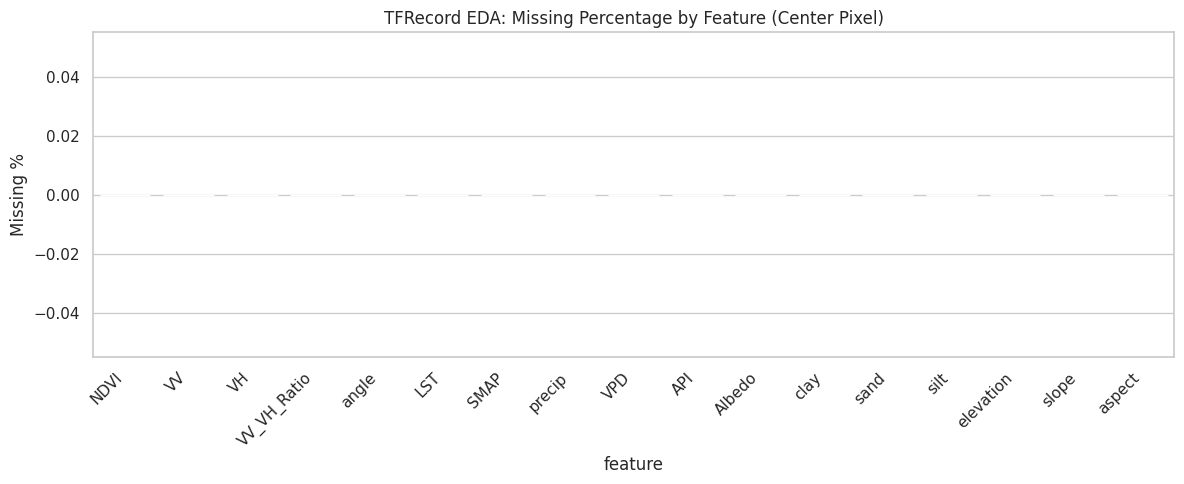

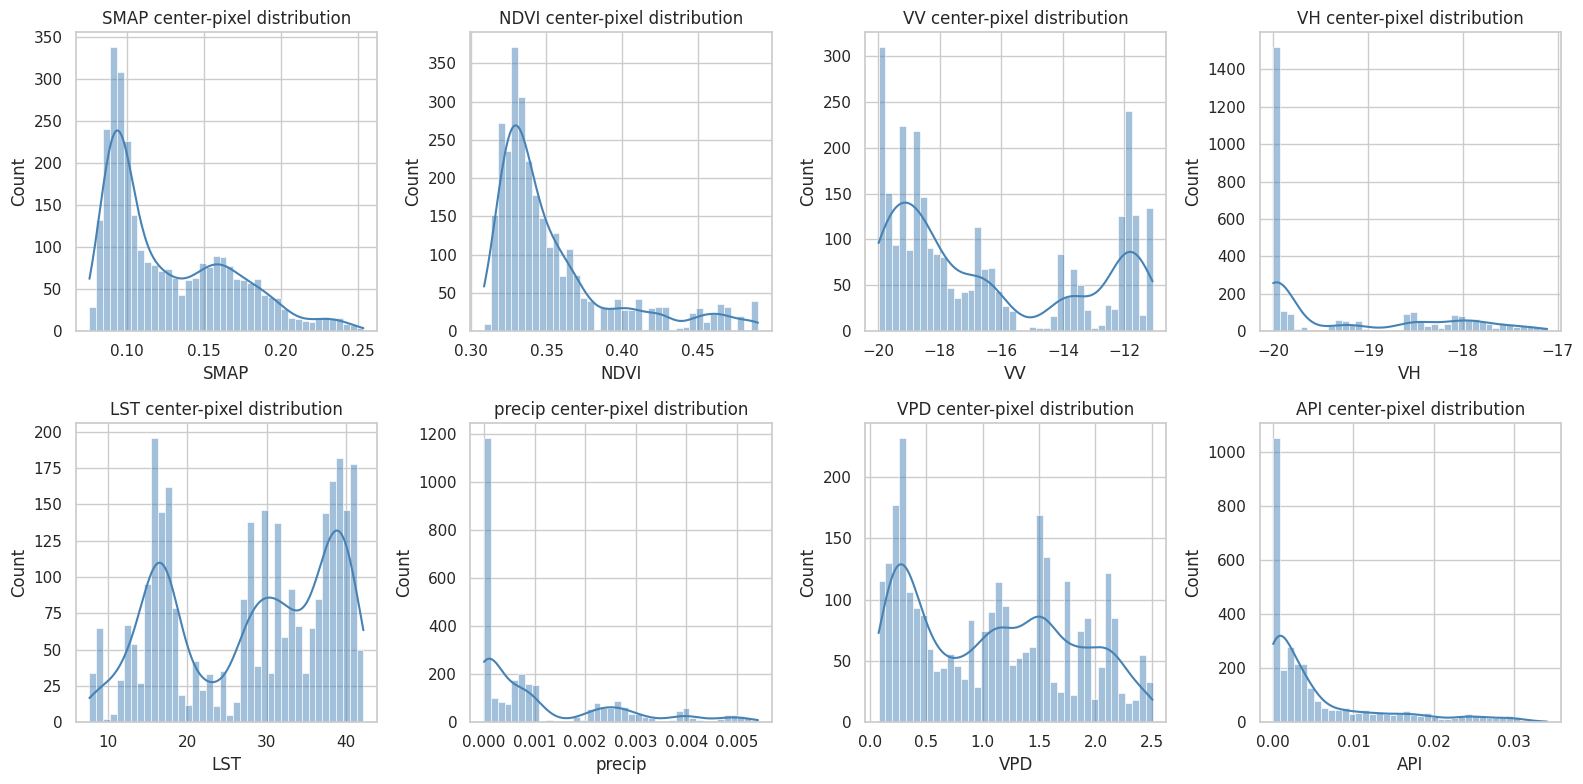

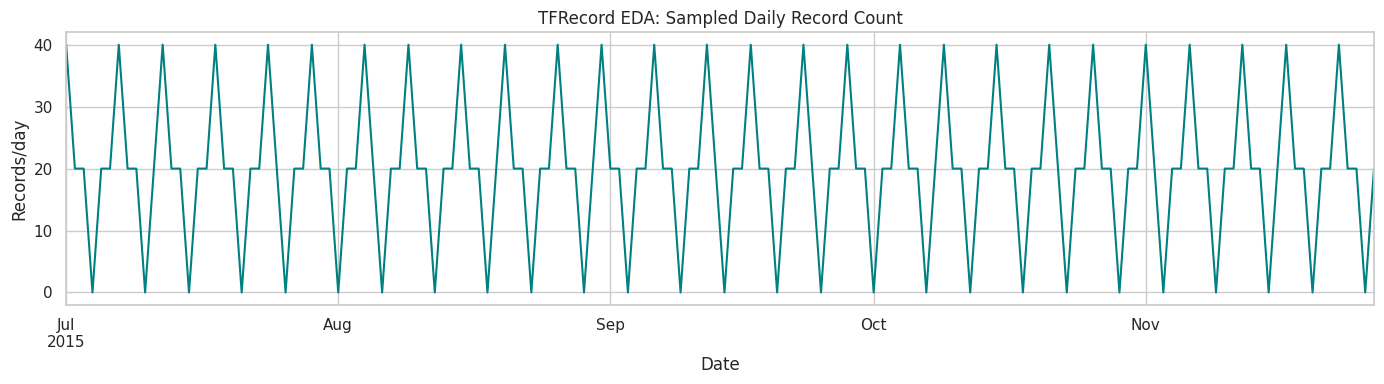

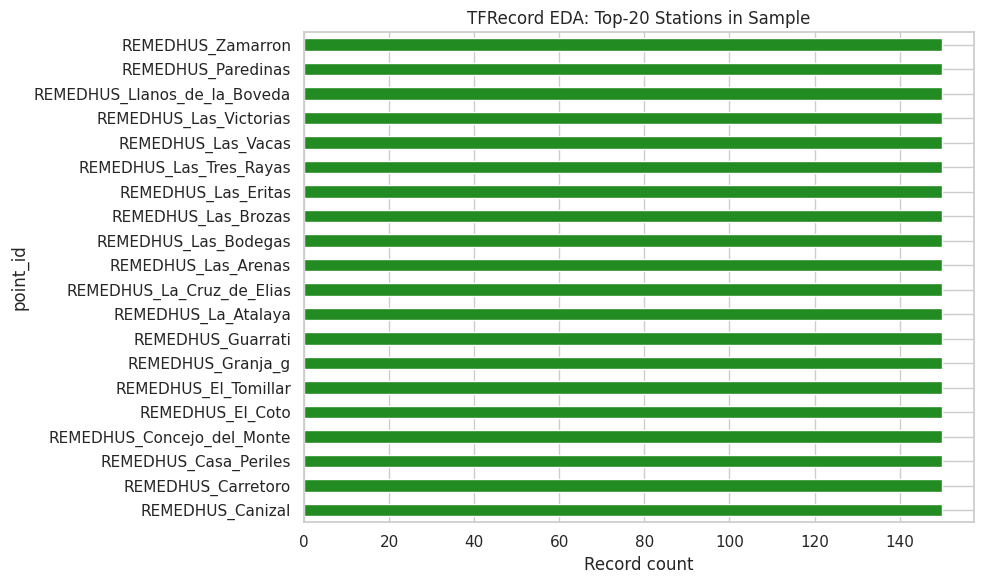

In [36]:
center_cols = [f'{f}_center' for f in features]
mean_cols = [f'{f}_mean' for f in features]
std_cols = [f'{f}_std' for f in features]

feature_summary = pd.DataFrame({
    'feature': features,
    'center_mean': [tfrecord_df[c].mean() for c in center_cols],
    'center_std': [tfrecord_df[c].std() for c in center_cols],
    'patch_mean_avg': [tfrecord_df[c].mean() for c in mean_cols],
    'patch_std_avg': [tfrecord_df[c].mean() for c in std_cols],
    'center_missing_pct': [100.0 * tfrecord_df[c].isna().mean() for c in center_cols],
})
feature_summary = feature_summary.sort_values('center_missing_pct', ascending=False)
feature_summary

plt.figure(figsize=(12, 5))
sns.barplot(data=feature_summary, x='feature', y='center_missing_pct', color='tomato')
plt.xticks(rotation=45, ha='right')
plt.title('TFRecord EDA: Missing Percentage by Feature (Center Pixel)')
plt.ylabel('Missing %')
plt.tight_layout()
plt.show()

plot_features = ['SMAP', 'NDVI', 'VV', 'VH', 'LST', 'precip', 'VPD', 'API']
available_plot_features = [f for f in plot_features if f in features]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for idx, feat in enumerate(available_plot_features):
    col = f'{feat}_center'
    sns.histplot(tfrecord_df[col].dropna(), bins=40, kde=True, ax=axes[idx], color='steelblue')
    axes[idx].set_title(f'{feat} center-pixel distribution')
    axes[idx].set_xlabel(feat)

for j in range(len(available_plot_features), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

if tfrecord_df['timestamp'].notna().any():
    ts_counts = tfrecord_df.set_index('timestamp').resample('D').size()
    plt.figure(figsize=(14, 4))
    ts_counts.plot(color='teal')
    plt.title('TFRecord EDA: Sampled Daily Record Count')
    plt.xlabel('Date')
    plt.ylabel('Records/day')
    plt.tight_layout()
    plt.show()

station_counts_tf = tfrecord_df['point_id'].value_counts().head(20).sort_values()
plt.figure(figsize=(10, 6))
station_counts_tf.plot(kind='barh', color='forestgreen')
plt.title('TFRecord EDA: Top-20 Stations in Sample')
plt.xlabel('Record count')
plt.tight_layout()
plt.show()

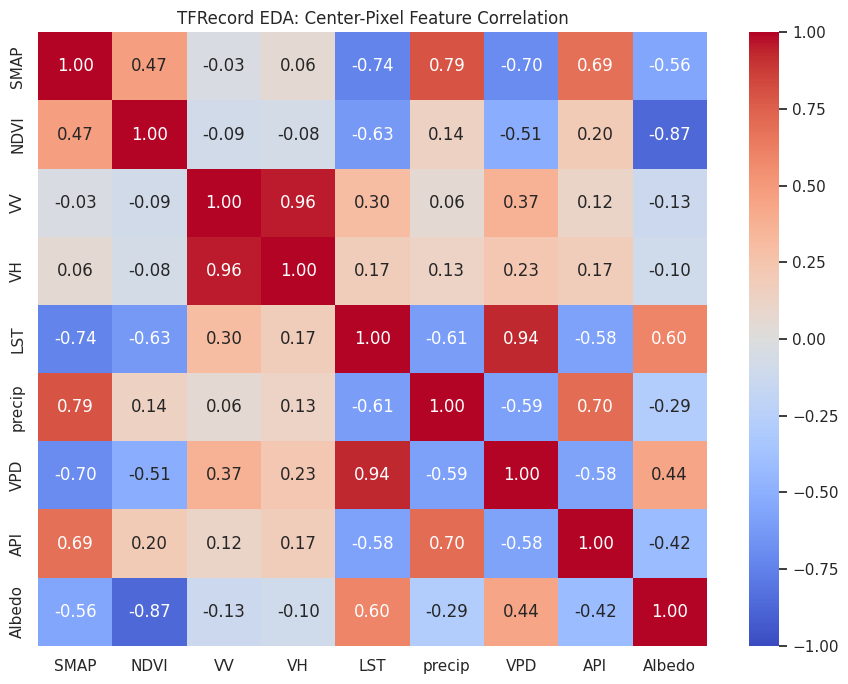

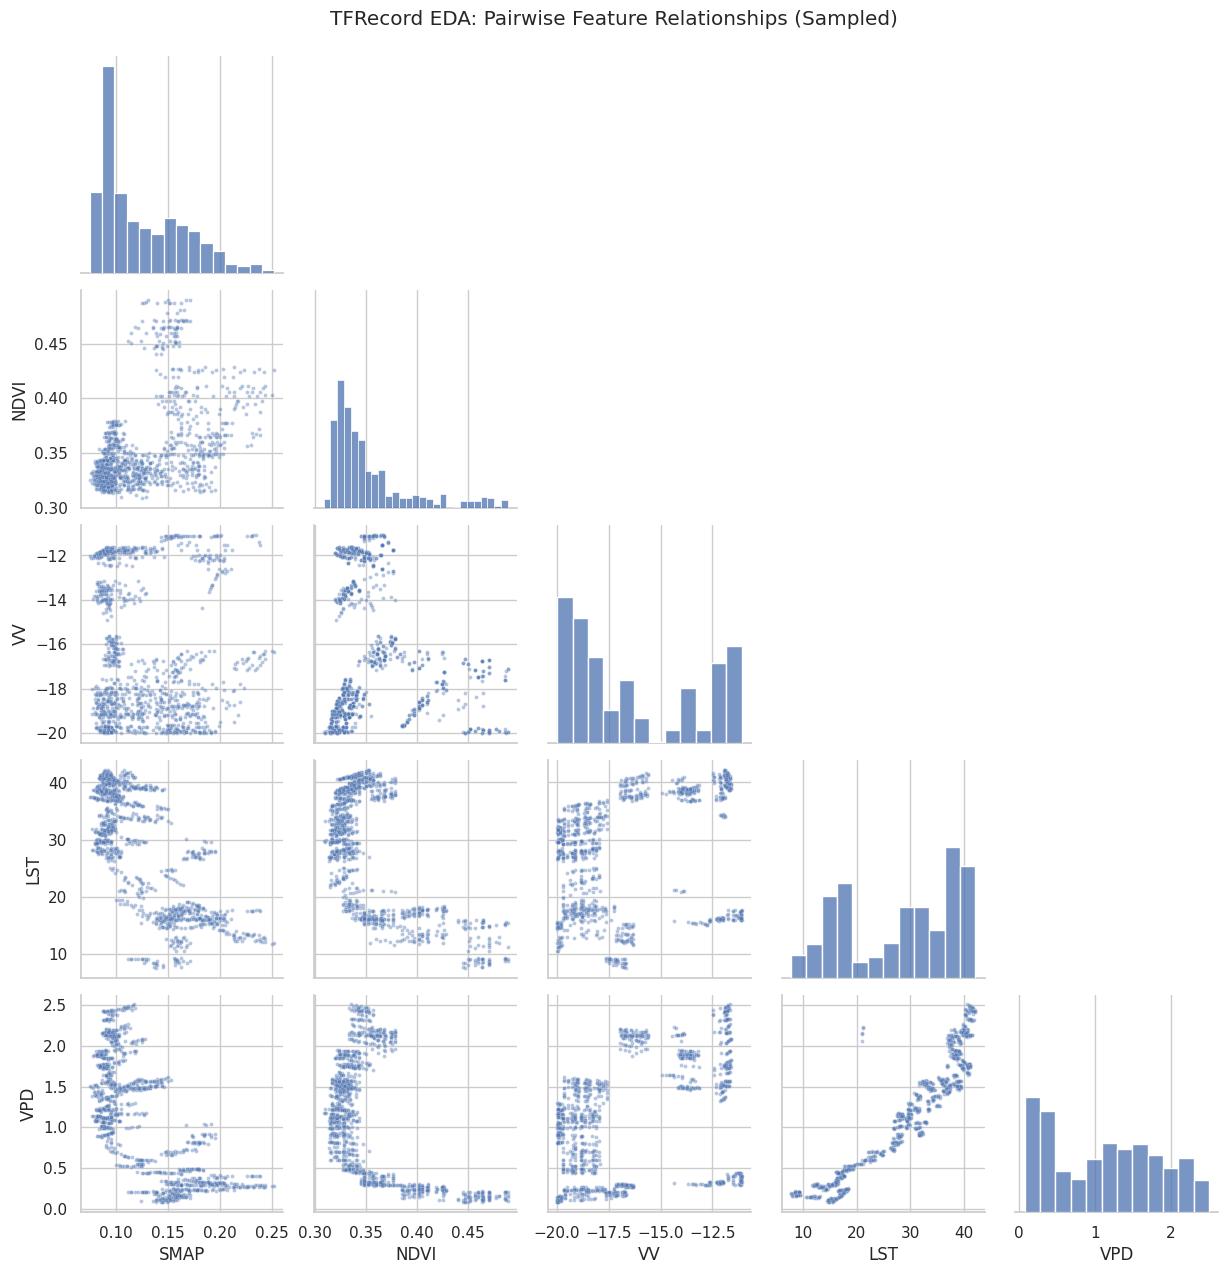

In [39]:
corr_features = ['SMAP', 'NDVI', 'VV', 'VH', 'LST', 'precip', 'VPD', 'API', 'Albedo']
corr_cols = [f'{f}_center' for f in corr_features if f'{f}_center' in tfrecord_df.columns]

corr_data = tfrecord_df[corr_cols].copy()
corr_data = corr_data.rename(columns={c: c.replace('_center', '') for c in corr_data.columns})
corr_matrix = corr_data.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('TFRecord EDA: Center-Pixel Feature Correlation')
plt.tight_layout()
plt.show()

pairplot_features = ['SMAP', 'NDVI', 'VV', 'LST', 'VPD']
pairplot_cols = [f'{f}_center' for f in pairplot_features if f'{f}_center' in tfrecord_df.columns]
pairplot_df = tfrecord_df[pairplot_cols].copy().dropna()
pairplot_df = pairplot_df.rename(columns={c: c.replace('_center', '') for c in pairplot_df.columns})

pairplot_n = min(1200, len(pairplot_df))
if pairplot_n > 10:
    sns.pairplot(pairplot_df.sample(pairplot_n, random_state=42), corner=True, plot_kws={'s': 8, 'alpha': 0.4})
    plt.suptitle('TFRecord EDA: Pairwise Feature Relationships (Sampled)', y=1.02)
    plt.show()

Stations mapped: 20


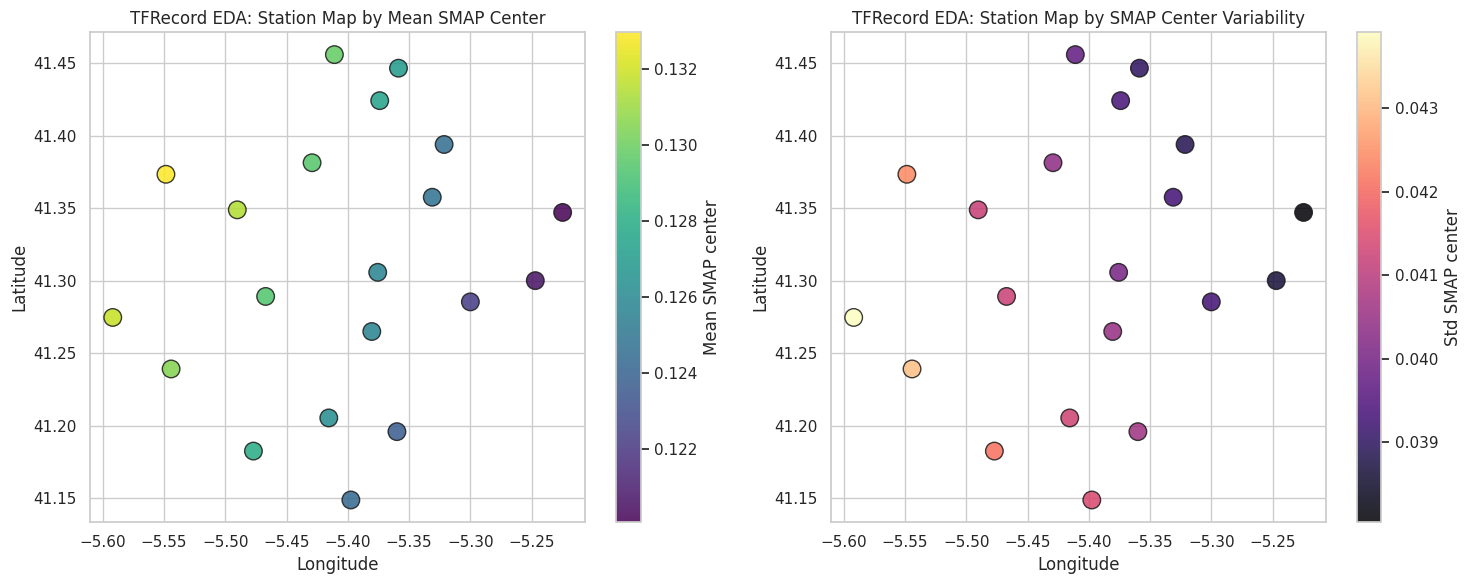

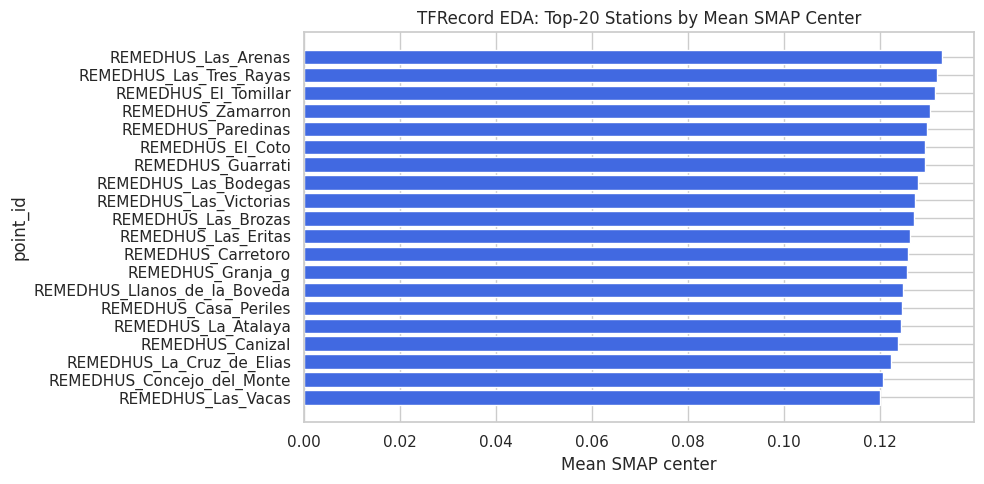

In [40]:
station_tf = tfrecord_df.groupby('point_id', as_index=False).agg(
    SMAP_center_mean=('SMAP_center', 'mean'),
    SMAP_center_std=('SMAP_center', 'std'),
    NDVI_center_mean=('NDVI_center', 'mean'),
    sample_count=('point_id', 'size')
)

coord_source = None
if 'df' in globals() and all(c in df.columns for c in ['point_id', 'latitude', 'longitude']):
    coord_source = df[['point_id', 'latitude', 'longitude']].drop_duplicates('point_id')
elif 'ground_truth' in globals() and all(c in ground_truth.columns for c in ['point_id', 'latitude', 'longitude']):
    coord_source = ground_truth[['point_id', 'latitude', 'longitude']].drop_duplicates('point_id')

if coord_source is None or coord_source.empty:
    print('Spatial map skipped: station coordinates not available in current session.')
else:
    station_map = station_tf.merge(coord_source, on='point_id', how='left')
    station_map = station_map.dropna(subset=['latitude', 'longitude'])
    print(f'Stations mapped: {len(station_map)}')

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sc1 = axes[0].scatter(
        station_map['longitude'], station_map['latitude'],
        c=station_map['SMAP_center_mean'], s=40 + 0.8 * station_map['sample_count'],
        cmap='viridis', edgecolor='k', alpha=0.85
    )
    axes[0].set_title('TFRecord EDA: Station Map by Mean SMAP Center')
    axes[0].set_xlabel('Longitude')
    axes[0].set_ylabel('Latitude')
    plt.colorbar(sc1, ax=axes[0], label='Mean SMAP center')

    sc2 = axes[1].scatter(
        station_map['longitude'], station_map['latitude'],
        c=station_map['SMAP_center_std'], s=40 + 0.8 * station_map['sample_count'],
        cmap='magma', edgecolor='k', alpha=0.85
    )
    axes[1].set_title('TFRecord EDA: Station Map by SMAP Center Variability')
    axes[1].set_xlabel('Longitude')
    axes[1].set_ylabel('Latitude')
    plt.colorbar(sc2, ax=axes[1], label='Std SMAP center')

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))
    top_smap = station_map.sort_values('SMAP_center_mean', ascending=False).head(20)
    plt.barh(top_smap['point_id'][::-1], top_smap['SMAP_center_mean'][::-1], color='royalblue')
    plt.title('TFRecord EDA: Top-20 Stations by Mean SMAP Center')
    plt.xlabel('Mean SMAP center')
    plt.ylabel('point_id')
    plt.tight_layout()
    plt.show()